# Phase 2c -- Side analyses of the pair test

These analyses re-use the Phase 2 test but are **not** part of its main line (notebook 02). They
describe other patient groups or check specific concerns, and none changes the 1,584 interaction
candidates. Validation of the main result is in notebook 02b.

| Section | Question |
|---|---|
| A | What do hypermutated tumours show on their own? |
| B | What if only mutations count (every patient with mutation data)? |
| C | Which alteration types carry each signal (mutation vs copy number on each side)? |
| D | Copy-number burden: do co-occurrences survive grouping patients by genome instability? |
| E | Fusion screen: what goes with ALK, ROS1, RET, ERG ...? |
| F | The same gene list in every cancer type |
| G | Which pairs recur across cancer types? |
| H | An example: the 11q13 / 8p12 co-amplification in breast cancer |
| I | Exclusive gene *sets*, not pairs (Dendrix / MEMo idea) |
| J | Does gene A change selection on gene B? (dN/dS idea) |
| K | Borrowing strength across cancer types (hierarchical idea) |
| L | Is the result driven by mutation load? (van de Haar 2019 diagnostic) |
| M | Ranking by effect size: whose strongest pairs replicate best? |

Run after notebook 02. Sections I-M read the outputs of `scripts/analyses/15-18` and `21`. Section D adds the `burden_*` columns to `comutation_pairs.parquet`.

## Setup: the Phase 2 settings, data and test (from notebook 02)

In [1]:
import json
from contextlib import contextmanager

# Run notebook 02's settings, data-loading and test cells, so this notebook uses exactly the same
# patients, filters and test (cells are looked up by id, which does not change when text is edited).
_nb02 = {c.get("id"): "".join(c["source"]) for c in json.load(open("02_phase2_comutation_matrix.ipynb"))["cells"]}
for _cid in ["8455b24e", "57159198", "332f818c", "e3d5f851", "disc0v3rcd", "17d9c817", "056ff63e"]:
    exec(_nb02[_cid], globals())
main_cancer_types = qualifying_cancer_types   # as in notebook 02, Step 3


@contextmanager
def analysing(**overrides):
    """Temporarily swap notebook-level settings/data (e.g. which patients), then restore."""
    saved = {k: globals()[k] for k in overrides}
    globals().update(overrides)
    try:
        yield
    finally:
        globals().update(saved)


comutation_pairs = pd.read_parquet(PROCESSED_DIR / "comutation_pairs.parquet")
mechanism_pairs = pd.read_parquet(PROCESSED_DIR / "mechanism_pairs.parquet")
print(f"Phase 2 table: {len(comutation_pairs):,} pairs, {comutation_pairs['interaction_candidate'].sum():,} candidates")

one sample per patient: 271,837 samples -> 227,696 patients


main analysis group (not_hypermutated): 159,390 of 227,696 patients
(831438, 18) (53368, 6) (12486, 2) (159390, 27)
CNV_Driver_Status
Driver_Consistent    170990
Unannotated           42478
56 of 109 cancer types have >= 100 copy-number-tested patients
Phase 2 table: 6,697 pairs, 1,584 candidates


## A. Hypermutated tumours on their own

TMB 10-100 only: ultramutated tumours (TMB >= 100, mostly POLE) are a different mutational process --
pooled with the rest they made 21.6% of endometrial pairs "significant" (0.3% and 0% when separated).
Result: a description of mostly subtype structure (MSI vs MSS), not new interactions (notebook 04, Section 5).

In [2]:
# --- (2) Hypermutated patients on their own ---------------------------------
# TMB 10-100 only: ultramutated tumours (TMB >= 100, mostly POLE) are a different
# mutational process -- pooled with the rest they made 21.6% of endometrial pairs
# "significant" (0.3% and 0% when separated) -- and too few per cancer type to test.
status_summary = []
for ct in qualifying_cancer_types:
    ct_all = clinical_all[(clinical_all["CANCER_TYPE"] == ct) & clinical_all["CNA_TESTED"]]
    counts = ct_all["HYPERMUTATION_STATUS"].value_counts()
    status_summary.append({"Cancer_Type": ct, "n_total": int(len(ct_all)),
                           **{f"n_{k}": int(counts.get(k, 0)) for k in ("hypermutated", "not_hypermutated", "unknown")},
                           "n_ultramutated": int((ct_all["TMB_MUT_PER_MB"] >= ULTRAMUTATED_TMB).sum())})
pd.DataFrame(status_summary).to_parquet(PROCESSED_DIR / "hypermutation_status_by_cancer_type.parquet", index=False)

hyper_patients = clinical_all[(clinical_all["HYPERMUTATION_STATUS"] == "hypermutated")
                              & (clinical_all["TMB_MUT_PER_MB"] < ULTRAMUTATED_TMB)]
hyper_frames = []
with analysing(clinical=hyper_patients,
               alterations=alterations_all[alterations_all["Sample_ID"].isin(hyper_patients["SAMPLE_ID"])]):
    for ct in tqdm(qualifying_cancer_types, desc="hypermutated group"):
        res = test_cancer_type(ct, require_cna_tested=True)
        if not res.empty:
            res["q_value"] = bh_fdr(res["p_value"].to_numpy())
            hyper_frames.append(res)
comutation_pairs_hyper = pd.concat(hyper_frames, ignore_index=True)
comutation_pairs_hyper.to_parquet(PROCESSED_DIR / "comutation_pairs_hypermutated.parquet", index=False)
print(f"hypermutated group (TMB 10-{ULTRAMUTATED_TMB}): {len(comutation_pairs_hyper):,} pairs in "
      f"{comutation_pairs_hyper['Cancer_Type'].nunique()} cancer types, "
      f"{(comutation_pairs_hyper['q_value'] < 0.05).sum():,} significant")


hypermutated group:   0%|          | 0/56 [00:00<?, ?it/s]

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:267: RuntimeWarning: overflow encountered in multiply
<string>:274: RuntimeWarning: overflow encountered in multiply


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:267: RuntimeWarning: overflow encountered in multiply
<string>:274: RuntimeWarning: overflow encountered in multiply


...

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:267: RuntimeWarning: overflow encountered in multiply
<string>:274: RuntimeWarning: overflow encountered in multiply


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:267: RuntimeWarning: overflow encountered in multiply
<string>:274: RuntimeWarning: overflow encountered in multiply


hypermutated group (TMB 10-100): 98,907 pairs in 18 cancer types, 881 significant


## B. Mutations only

"Altered" = protein-changing mutation only, so copy-number data are not needed and every patient with
mutation data counts. Mutation calls are the most consistent between centres (replication 84%), and the
directions agree with the main analysis in 98.9% of pairs significant in both (notebook 04, Step 4).

In [3]:
# --- (3) Mutation-only analysis ---------------------------------------------
# "Altered" = protein-changing mutation only, so copy-number data is not needed and
# every patient with mutation data counts (not just the copy-number-tested ones).
mut_alterations = alterations[alterations["Alteration_Type"] == "MUT"]
mut_counts = clinical.loc[clinical["MUT_TESTED"], "CANCER_TYPE"].value_counts()
mut_cancer_types = [ct for ct in mut_counts[mut_counts >= MIN_SAMPLES_PER_CANCER_TYPE].index
                    if ct not in EXCLUDED_CANCER_TYPES]
mut_frames = []
for ct in tqdm(mut_cancer_types, desc="mutation-only"):
    res = test_cancer_type(ct, alt_source=mut_alterations, mutation_only=True)
    if not res.empty:
        res["q_value"] = bh_fdr(res["p_value"].to_numpy())
        mut_frames.append(res)
comutation_pairs_mut = pd.concat(mut_frames, ignore_index=True)
comutation_pairs_mut.to_parquet(PROCESSED_DIR / "comutation_pairs_mutation_only.parquet", index=False)
print(f"mutation-only: {len(comutation_pairs_mut):,} pairs in {len(mut_frames)} cancer types "
      f"({mut_counts[mut_cancer_types].sum():,} patients), "
      f"{(comutation_pairs_mut['q_value'] < 0.05).sum():,} significant")


mutation-only:   0%|          | 0/61 [00:00<?, ?it/s]

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

...

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

mutation-only: 2,403 pairs in 57 cancer types (155,020 patients), 573 significant


## C. Which alteration types carry each signal

The tests themselves run in notebook 02 (Step 5a), because the neighbouring-gene rule needs the mutation-only result. Here: the cross-mechanism hits that no single alteration type can see.

The runs above score a gene as altered if it carries **either** a mutation or a
copy-number change, which cannot distinguish "these two genes are both mutated"
from "one is mutated and the other is amplified". Those are different biological
claims, and they can point in opposite directions for the same pair.

So each pair is also tested four ways, mutation and copy-number treated
separately on each side:

| test | question |
|---|---|
| A-SNV x B-SNV | do point mutations in A and B co-occur? |
| A-SNV x B-CNV | does mutating A go with copy-number change in B? |
| A-CNV x B-SNV | the reverse -- asymmetric, so both are needed |
| A-CNV x B-CNV | do the copy-number events co-occur? |

Each test uses the same conditional test as the main run (Step 3),
with one change: a patient's SNV
burden and CNV burden are different biological quantities (point-mutation
hypermutation vs. chromosomal instability aren't the same patient property),
so each mechanism gets its **own** conditional model -- conditioned on the
patient's mutation count and copy-number count separately. A same-mechanism
pair uses the joint conditional probability; a cross-mechanism pair (e.g.
A-SNV x B-CNV) uses the product of the two marginal ones. Each combination gets its own BH-FDR family (a q-value in the SNV-SNV
family shouldn't depend on how many CNV-CNV pairs happened to be testable).
All four share one denominator -- the CNA-tested samples of that cancer type
-- so the four results for a pair are directly comparable to each other.

The cross-mechanism tests are the ones that earn their place: `MDM2`
amplification vs `TP53` mutation is strongly mutually exclusive, and **no**
single-mechanism matrix can see it, because it needs one gene's copy-number
state compared against the other gene's mutation status.

In [4]:
# Cross-mechanism hits -- invisible to any single-mechanism matrix
sig_mech = mechanism_pairs[mechanism_pairs["q_value"] < 0.05]
cross = sig_mech[sig_mech["mech_A"] != sig_mech["mech_B"]]
print(f"significant cross-mechanism results: {len(cross):,}\n")
print("Strongest mutual exclusivity:")
print(cross.nsmallest(10, "fold_enrichment")[
    ["Cancer_Type", "Gene_A", "mech_A", "Gene_B", "mech_B", "n_tested_both",
     "n_both_altered", "expected_both", "fold_enrichment", "q_value"]].to_string(index=False))

# Pairs whose direction flips depending on which mechanisms are compared --
# exactly what the blended matrix averages away.
flip = sig_mech.copy()
flip["pair"] = [tuple(sorted([a, b])) for a, b in zip(flip["Gene_A"], flip["Gene_B"])]
conflicts = [(ct, pr, g) for (ct, pr), g in flip.groupby(["Cancer_Type", "pair"])
             if (g["direction"] == "co-occurring").any() and (g["direction"] == "exclusive").any()]
print(f"\n{len(conflicts)} pairs significant in BOTH directions depending on mechanism "
      f"(of {flip['pair'].nunique():,} significant pairs)")
for ct, pr, g in conflicts[:10]:
    print(f"  {ct:26s} {pr[0]}-{pr[1]:9s} " +
          " | ".join(f"{r.combo} fold={r.fold_enrichment:.2f} ({r.direction})" for r in g.itertuples()))

significant cross-mechanism results: 687

Strongest mutual exclusivity:
              Cancer_Type Gene_A mech_A Gene_B mech_B  n_tested_both  n_both_altered  expected_both  fold_enrichment      q_value
                   Glioma   IDH1    SNV   MDM2    CNV           6419               0      27.007657         0.018177 5.514883e-11
     Head and Neck Cancer CDKN2A    SNV CDKN2B    CNV           1204               0      17.395204         0.027940 8.522018e-07
     Hepatobiliary Cancer CDKN2A    SNV CDKN2B    CNV           2769               0      15.239216         0.031768 1.476126e-05
        Pancreatic Cancer CDKN2A    SNV CDKN2B    CNV           6928               7     213.525934         0.035042 3.625925e-93
Cancer of Unknown Primary CDKN2A    SNV   MTAP    CNV           3230               0      13.639878         0.035361 4.779555e-05
        Pancreatic Cancer CDKN2A    SNV   MTAP    CNV           6825               3      96.847678         0.035954 1.888430e-39
           Bladder

## D. Copy-number burden (sensitivity flag)

The conditional test conditions on each patient's *total* number of alterations, but a gene that
sits on an unmeasured amplicon can still act as a marker of a generally unstable, "amplifier"
tumour and pair with other amplified genes for that reason alone. This concern has published
precedent: CDCOCA (Kumar et al. 2011) and Zack et al. 2013 both found that copy-number
co-occurrence must be judged against each tumour's overall copy-number complexity.

Building burden into the main test was tried (`scripts/analyses/13_burden_strata.py`):
counting burden from all genes over-adjusts -- a pair amplified together raises its own
patient's burden, so the famous breast *CCND1*/*FGFR1* co-amplification disappeared; counting
only genes *outside* the analysis avoids that but did not improve out-of-centre replication
(64% vs 66%). So burden is used as a **sensitivity check** rather than the default: every pair
is re-tested with gene rates fitted within subtype x burden groups (0 / 1-3 / >= 4 deep
copy-number calls in genes outside the analysis), and `burden_robust` records whether a
significant pair survives.

In [5]:
cnv_rows = alterations[alterations["Alteration_Type"] == "CNV"]
sens_frames = []
for ct, ct_pairs in tqdm(comutation_pairs.groupby("Cancer_Type"), desc="burden sensitivity"):
    genes = set(ct_pairs["Gene_A"]) | set(ct_pairs["Gene_B"])
    outside = cnv_rows[(cnv_rows["CANCER_TYPE"] == ct) & ~cnv_rows["Hugo_Symbol"].isin(genes)]
    n_cnv = clinical["SAMPLE_ID"].map(outside.groupby("Sample_ID").size()).fillna(0)
    group = np.select([n_cnv == 0, n_cnv <= 3], ["cnv0", "cnv1-3"], "cnv4+")
    with analysing(clinical=clinical.assign(BURDEN_STRATUM=clinical["SUBTYPE_STRATUM"] + "|" + group),
                   STRATUM_COLUMN="BURDEN_STRATUM"):
        res = test_cancer_type(ct, allowed_genes=genes, require_cna_tested=True)
    if not res.empty:
        res["burden_q_value"] = bh_fdr(res["p_value"].to_numpy())
        sens_frames.append(res.rename(columns={"direction": "burden_direction"})[
            ["Cancer_Type", "Gene_A", "Gene_B", "burden_q_value", "burden_direction"]])
# drop any burden columns from an earlier run, so re-running this section gives the same table
comutation_pairs = comutation_pairs.drop(columns=["burden_q_value", "burden_direction", "burden_robust"], errors="ignore")
comutation_pairs = comutation_pairs.merge(pd.concat(sens_frames, ignore_index=True),
                                          on=["Cancer_Type", "Gene_A", "Gene_B"], how="left")
comutation_pairs["burden_robust"] = ((comutation_pairs["burden_q_value"] < 0.05)
                                     & (comutation_pairs["burden_direction"] == comutation_pairs["direction"]))
_sig = comutation_pairs["q_value"] < 0.05
print(f"significant pairs that survive the burden sensitivity check: "
      f"{(_sig & comutation_pairs['burden_robust']).sum():,} of {_sig.sum():,}")

burden sensitivity:   0%|          | 0/51 [00:00<?, ?it/s]

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


...

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


significant pairs that survive the burden sensitivity check: 1,506 of 1,824


In [6]:
comutation_pairs.to_parquet(PROCESSED_DIR / "comutation_pairs.parquet", index=False)
print("comutation_pairs.parquet updated with the burden_* columns")

comutation_pairs.parquet updated with the burden_* columns


## E. Fusion screen: what goes with ALK, ROS1, RET, ERG ...?

Gene fusions (Phase 1 Section 4c) are a third kind of alteration. Most are too rare to pass the
3% gene filter, yet they are exactly what clinicians ask about ("an ALK-fusion lung cancer --
what else should I expect?"). Each fusion with >= `MIN_FUSION_CARRIERS` carriers in a cancer
type is tested with the same conditional test against that cancer type's analysis genes and
against the other fusions, using only patients whose panel can detect it (filters 3 and 4
apply as usual; BH-FDR within each cancer type, across the fusion pairs).

In [7]:
fusion_rows = alterations[alterations["Alteration_Type"] == "SV"]
fus_frames = []
for ct in tqdm(qualifying_cancer_types, desc="fusion screen"):
    carriers = fusion_rows[fusion_rows["CANCER_TYPE"] == ct].groupby("Hugo_Symbol")["Sample_ID"].nunique()
    fusions_here = set(carriers[carriers >= MIN_FUSION_CARRIERS].index)
    if not fusions_here:
        continue
    ct_pairs = comutation_pairs[comutation_pairs["Cancer_Type"] == ct]
    genes = (set(ct_pairs["Gene_A"]) | set(ct_pairs["Gene_B"])) - set(fusion_rows["Hugo_Symbol"])
    with analysing(MIN_GENE_ALT_FRACTION=0.0, MIN_GENE_ALT_ABS=1):
        res = test_cancer_type(ct, allowed_genes=genes | fusions_here, require_cna_tested=True)
    if res.empty:
        continue
    res = res[res["Gene_A"].isin(fusions_here) | res["Gene_B"].isin(fusions_here)].copy()
    if res.empty:
        continue
    res["q_value"] = bh_fdr(res["p_value"].to_numpy())
    fus_frames.append(res)
comutation_pairs_fusions = pd.concat(fus_frames, ignore_index=True)
comutation_pairs_fusions.to_parquet(PROCESSED_DIR / "comutation_pairs_fusions.parquet", index=False)
_s = comutation_pairs_fusions[comutation_pairs_fusions["q_value"] < 0.05]
print(f"fusion screen: {len(comutation_pairs_fusions):,} pairs in {comutation_pairs_fusions['Cancer_Type'].nunique()} "
      f"cancer types, {len(_s):,} significant ({(_s['direction'] == 'exclusive').sum():,} exclusive)")
_s.sort_values("q_value")[["Cancer_Type", "Gene_A", "Gene_B", "n_both_altered", "expected_both",
                           "fold_enrichment", "direction", "q_value"]].head(20)

fusion screen:   0%|          | 0/56 [00:00<?, ?it/s]

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


...

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

fusion screen: 255 pairs in 13 cancer types, 109 significant (92 exclusive)


,Cancer_Type,Gene_A,Gene_B,n_both_altered,expected_both,fold_enrichment,direction,q_value
24,Non-Small Cell Lung Cancer,ALK_fusion,EGFR,4,140.364585,0.031946,exclusive,2.881215e-53
195,Prostate Cancer,ERG_fusion,SPOP,11,149.595700,0.076618,exclusive,4.130203e-51
30,Non-Small Cell Lung Cancer,ALK_fusion,KRAS,5,132.016830,0.041504,exclusive,1.701430e-48
45,Non-Small Cell Lung Cancer,ALK_fusion,STK11,0,59.156789,0.008381,exclusive,7.453840e-25
83,Non-Small Cell Lung Cancer,KRAS,RET_fusion,2,61.454764,0.040352,exclusive,1.209662e-22
84,Non-Small Cell Lung Cancer,KRAS,ROS1_fusion,0,48.991715,0.010103,exclusive,1.505816e-20
70,Non-Small Cell Lung Cancer,EGFR,ROS1_fusion,2,52.639562,0.047046,exclusive,4.624512e-19
187,Prostate Cancer,ERG_fusion,FOXA1,77,178.989587,0.431780,exclusive,1.852805e-18
69,Non-Small Cell Lung Cancer,EGFR,RET_fusion,9,65.146455,0.144715,exclusive,6.291282e-17
183,Prostate Cancer,CDK12,ERG_fusion,6,54.710017,0.117732,exclusive,3.949992e-16


Figure -- Phase 2c at a glance. **a** the same in individual patients: each column is a lung cancer, each row a gene; the main drivers (incl. fusions) form a staircase -- most tumours carry only one of them; **b** fusion partners: ALK, ROS1 and RET fusions avoid EGFR, KRAS and STK11 in lung cancer; ERG fusions avoid SPOP and FOXA1 in prostate cancer.  
*Drawn by `scripts/figures/phase2c_extensions.R` -> `results/figures/phase2c_extensions/figure_phase2c.pdf`*

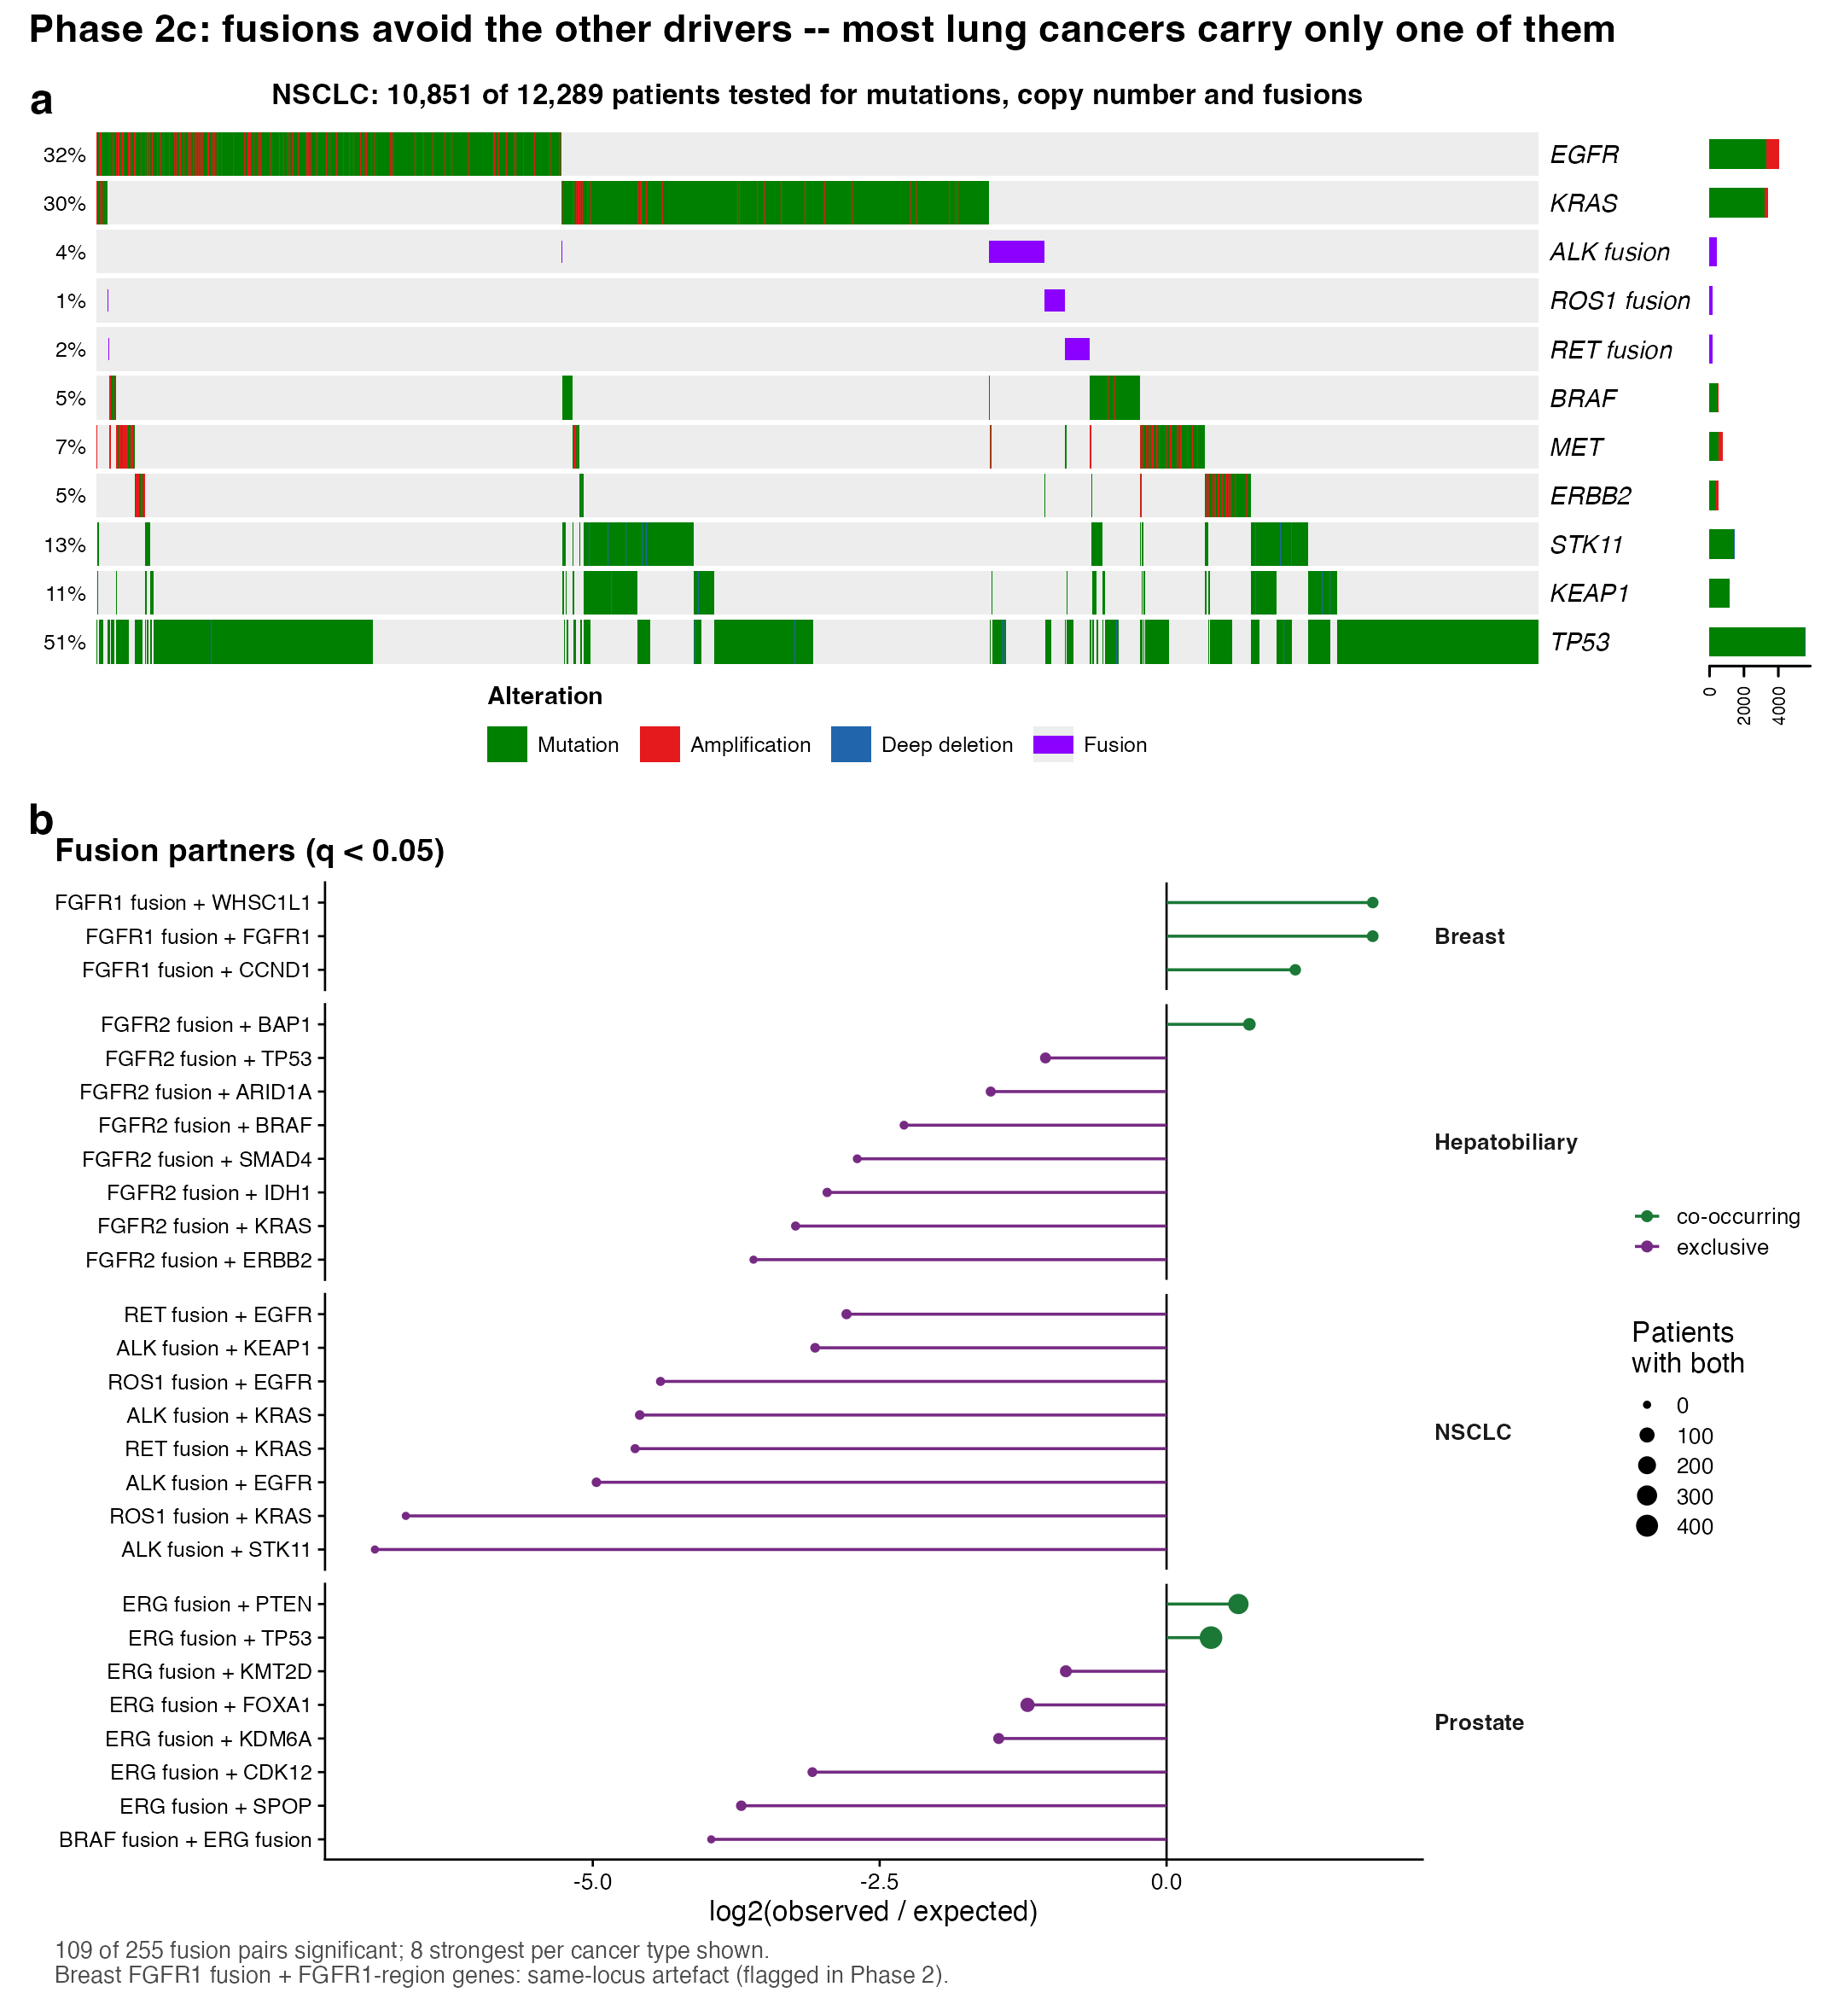

In [8]:
import subprocess, sys
from IPython.display import Image, display

# Rebuild this phase's figure from the saved outputs: export small CSVs, then run the R script
subprocess.run([sys.executable, "scripts/figures/00_export_figure_data.py"], cwd="..", check=True, capture_output=True)
subprocess.run(["Rscript", "scripts/figures/phase2c_extensions.R"], cwd="..", check=True, capture_output=True)
display(Image(filename="../results/figures/phase2c_extensions/figure_phase2c.png", width=1000))

## F. The same gene list in every cancer type

The main analysis lets each cancer type use its own frequently altered genes. Here every cancer type
uses one shared list (genes sequenced for >= 80% of patients), so cancer types can be compared directly.

In [9]:
# Genes for the main run come straight from filter 2 (frequency) inside each
# cancer type -- no separate pre-made list.
# The global run instead uses ONE gene list for every cancer type: genes
# sequenced for >= 80% of ALL patients, so cancer types can be compared.
GLOBAL_GENE_COVERAGE = 0.80
_tested_patients = (panel_coverage.merge(clinical[["SAMPLE_ID", "SEQ_ASSAY_ID"]], on="SEQ_ASSAY_ID")
                    .groupby("Hugo_Symbol")["SAMPLE_ID"].nunique())
global_genes = set(_tested_patients[_tested_patients >= GLOBAL_GENE_COVERAGE * len(clinical)].index)
print(f"global gene list: {len(global_genes)} genes sequenced for >= {GLOBAL_GENE_COVERAGE:.0%} of "
      f"{len(clinical):,} patients")


global gene list: 275 genes sequenced for >= 80% of 159,390 patients


In [10]:
# --- Global-gene run: same 190-gene list for every cancer type, for
# direct cross-cancer-type comparison ---
all_results_global = []
for ct in tqdm(main_cancer_types, desc="global (same 190 genes everywhere)"):
    res = test_cancer_type(ct, global_genes, require_cna_tested=True)
    if not res.empty:
        res["q_value"] = bh_fdr(res["p_value"].to_numpy())
        all_results_global.append(res)

comutation_pairs_global = pd.concat(all_results_global, ignore_index=True)
comutation_pairs_global.to_parquet(PROCESSED_DIR / "comutation_pairs_global_genes.parquet", index=False)
print("global-gene run:", comutation_pairs_global.shape)
n_sig_global = (comutation_pairs_global["q_value"] < 0.05).sum()
print(f"{n_sig_global:,} of {len(comutation_pairs_global):,} pairs significant at q < 0.05 "
      f"({n_sig_global / len(comutation_pairs_global):.1%})")
comutation_pairs_global.head()

global (same 190 genes everywhere):   0%|          | 0/56 [00:00<?, ?it/s]

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


...

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

global-gene run: (4947, 14)
1,260 of 4,947 pairs significant at q < 0.05 (25.5%)


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


,Cancer_Type,Gene_A,Gene_B,n_tested_both,n_both_altered,n_A_only,n_B_only,n_neither,expected_both,fold_enrichment,log2_fold_enrichment,direction,p_value,q_value
0,Breast Cancer,AKT1,ARID1A,12501,23,567,613,11298,31.639297,0.731192,-0.451678,exclusive,1.348844e-01,2.077603e-01
1,Breast Cancer,AKT1,AURKA,10880,16,491,370,10003,20.441699,0.787902,-0.343912,exclusive,3.849904e-01,4.926058e-01
2,Breast Cancer,AKT1,BRCA2,12805,12,590,379,11824,19.817087,0.615246,-0.700765,exclusive,8.344209e-02,1.381647e-01
3,Breast Cancer,AKT1,CBFB,11770,56,505,446,10763,25.437867,2.178282,1.123191,co-occurring,1.838963e-07,9.055501e-07
4,Breast Cancer,AKT1,CCND1,10880,66,441,1929,8444,101.097501,0.654544,-0.611439,exclusive,2.039286e-04,5.970882e-04


## G. Which pairs recur across cancer types?

Everything so far tests co-occurrence **within** one cancer type at a time
-- Aim 1 also asks for patterns **across** cancers. Pooling raw samples
from every cancer type into one big test was considered and rejected: it
would be dominated by whichever cancer type has the most samples (NSCLC:
39,553 vs. e.g. Medulloblastoma: 105) -- a classic Simpson's-paradox risk,
not a real cross-cancer signal.

Instead, this reuses the already-correct per-cancer-type results: for each
gene pair, count how many cancer types it's significant in, and whether
the direction (co-occurring vs. exclusive) is **consistent** across them.
A pair recurring with the same direction across many independent cancer
types is real evidence of a cross-cancer pattern; a pair that's
significant in one cancer type but flips direction in another reflects
real tissue-specific biology, not noise -- both are informative, but only
the first is a genuine "across cancers" finding.

In [11]:
PAN_CANCER_MIN_CANCER_TYPES = 5  # provisional -- how many cancer types before calling a pair "pan-cancer"

# Built on interaction candidates, not raw significance: a pair that recurs
# only because hypermutators or a shared amplicon drive it in every cancer
# type is recurring confounding, not a cross-cancer pattern.
sig = comutation_pairs[comutation_pairs["interaction_candidate"]].copy()
sig["pair_key"] = list(zip(sig["Gene_A"].where(sig["Gene_A"] < sig["Gene_B"], sig["Gene_B"]),
                            sig["Gene_B"].where(sig["Gene_A"] < sig["Gene_B"], sig["Gene_A"])))
# 'direction' (co-occurring / exclusive) already comes straight from the
# conditional test (notebook 02, Step 3) -- no need to re-derive it from an odds ratio.

pan_cancer = sig.groupby("pair_key").agg(
    n_cancer_types_significant=("Cancer_Type", "nunique"),
    cancer_types=("Cancer_Type", lambda s: sorted(set(s))),
    directions=("direction", lambda s: sorted(set(s))),
).reset_index()
pan_cancer["Gene_A"] = pan_cancer["pair_key"].apply(lambda t: t[0])
pan_cancer["Gene_B"] = pan_cancer["pair_key"].apply(lambda t: t[1])
pan_cancer["direction_consistent"] = pan_cancer["directions"].apply(len) == 1
pan_cancer["direction"] = pan_cancer["directions"].apply(lambda d: d[0] if len(d) == 1 else "mixed")
pan_cancer = pan_cancer.drop(columns="pair_key").sort_values("n_cancer_types_significant", ascending=False)

pan_cancer["is_pan_cancer_candidate"] = (
    (pan_cancer["n_cancer_types_significant"] >= PAN_CANCER_MIN_CANCER_TYPES) & pan_cancer["direction_consistent"]
)

n_candidates = pan_cancer["is_pan_cancer_candidate"].sum()
print(f"{n_candidates} pan-cancer candidate pairs (significant in >= {PAN_CANCER_MIN_CANCER_TYPES} cancer types, consistent direction)")
print()
print("Top 10 by recurrence:")
print(pan_cancer[["Gene_A", "Gene_B", "n_cancer_types_significant", "direction", "direction_consistent"]].head(10).to_string())

pan_cancer.to_parquet(PROCESSED_DIR / "pan_cancer_pairs.parquet", index=False)

13 pan-cancer candidate pairs (significant in >= 5 cancer types, consistent direction)

Top 10 by recurrence:
      Gene_A Gene_B  n_cancer_types_significant     direction  direction_consistent
547   CDKN2A   TP53                          12         mixed                 False
1073    MDM2   TP53                          11     exclusive                  True
579   CDKN2B    RB1                          10     exclusive                  True
539   CDKN2A    RB1                          10     exclusive                  True
170      ATM   TP53                           9     exclusive                  True
585   CDKN2B   TP53                           8     exclusive                  True
1163  PIK3CA   TP53                           7     exclusive                  True
1199     RB1   TP53                           7  co-occurring                  True
701    ERBB2   KRAS                           7     exclusive                  True
1187    PTEN   TP53                           7   

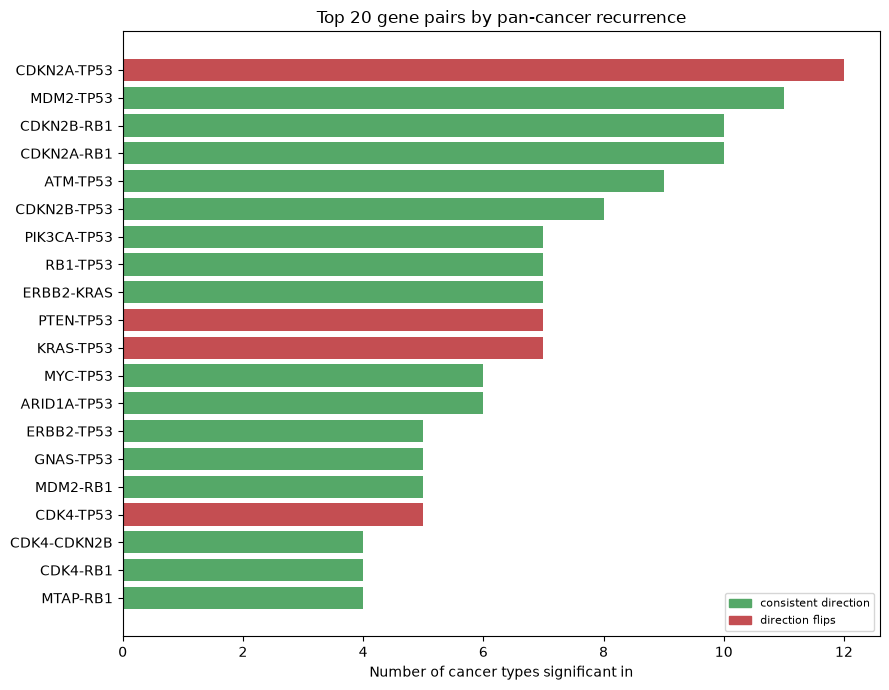

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))
top_pan = pan_cancer.sort_values("n_cancer_types_significant", ascending=False).head(20)
labels = [f"{a}-{b}" for a, b in zip(top_pan["Gene_A"], top_pan["Gene_B"])]
colors = top_pan["direction_consistent"].map({True: "#55A868", False: "#C44E52"})

ax.barh(labels[::-1], top_pan["n_cancer_types_significant"].values[::-1], color=colors.values[::-1])
ax.set_xlabel("Number of cancer types significant in")
ax.set_title("Top 20 gene pairs by pan-cancer recurrence")
ax.legend(
    handles=[Patch(color="#55A868", label="consistent direction"), Patch(color="#C44E52", label="direction flips")],
    fontsize=8, loc="lower right",
)
plt.tight_layout()
plt.show()

## H. An example: 11q13 / 8p12 co-amplification in breast cancer

The two things worth flagging from the results above:

1. **Top co-occurring pairs are dominated by `FGF19`/`FGF4`/`FGF3`/`CCND1`**,
   often with extreme (even infinite) fold enrichments. This is expected, not a
   bug: these 4 genes sit physically next to each other on chromosome
   11q13. When that region gets amplified, all of them get duplicated
   together as one physical event -- not because they cooperate
   biologically, but because they're neighbors on the same piece of DNA.

2. **11q13 genes co-occur with 8p12 genes (`FGFR1`, `WHSC1L1`) specifically
   in Breast Cancer**, and nowhere else with the same strength -- a
   recognized, subtype-specific finding in the literature (common in
   ER+/luminal B breast cancers), not a generic genomic artifact. Checked
   below.

In [13]:
genes_11q13 = ["CCND1", "FGF3", "FGF4", "FGF19"]
genes_8p12 = ["FGFR1", "WHSC1L1", "ZNF703", "NSD3"]

mask = (
    (comutation_pairs["Gene_A"].isin(genes_11q13) & comutation_pairs["Gene_B"].isin(genes_8p12))
    | (comutation_pairs["Gene_A"].isin(genes_8p12) & comutation_pairs["Gene_B"].isin(genes_11q13))
)
cross_region = comutation_pairs[mask].sort_values("q_value")
print(f"{len(cross_region)} cross 11q13-8p12 pairs tested")
cross_region[["Cancer_Type", "Gene_A", "Gene_B", "n_both_altered", "expected_both", "fold_enrichment", "direction", "q_value"]]

13 cross 11q13-8p12 pairs tested


,Cancer_Type,Gene_A,Gene_B,n_both_altered,expected_both,fold_enrichment,direction,q_value
164,Breast Cancer,CCND1,FGFR1,515,332.025450,1.550257,co-occurring,9.697301e-22
351,Breast Cancer,FGF3,FGFR1,343,221.183371,1.549507,co-occurring,1.115802e-14
369,Breast Cancer,FGF4,FGFR1,347,225.301735,1.538961,co-occurring,1.855179e-14
332,Breast Cancer,FGF19,FGFR1,356,233.216832,1.525350,co-occurring,2.527187e-14
182,Breast Cancer,CCND1,WHSC1L1,399,268.709214,1.483976,co-occurring,3.525861e-14
4430,Bladder Cancer,FGF4,WHSC1L1,11,8.933491,1.219061,co-occurring,7.878454e-01
4381,Bladder Cancer,FGF19,WHSC1L1,11,9.188552,1.186968,co-occurring,8.365459e-01
3955,Bladder Cancer,CCND1,WHSC1L1,14,12.242274,1.137944,co-occurring,8.732912e-01
3931,Bladder Cancer,CCND1,FGFR1,12,11.737077,1.021486,co-occurring,1.000000e+00
4358,Bladder Cancer,FGF19,FGFR1,9,8.684747,1.034324,co-occurring,1.000000e+00


**Result:** all 5 cross-region pairs testable in Breast Cancer come back
significantly co-occurring (about 1.5x the conditional expectation, q down to
~1e-21), while in Bladder Cancer there is no relationship at all (all q > 0.78).
(Endometrial Cancer, which showed these regions as exclusive in the previous,
hypermutation-pooled analysis, no longer has them among its frequent genes.) So
the pipeline reproduces the 11q13/8p12 co-amplification as breast-specific,
matching the literature. These pairs are copy-number events on two different
chromosomes, so the shared-DNA filter correctly does not remove them.

## I. Exclusive gene sets (Dendrix / MEMo idea)

Pairs miss groups of three or more genes that substitute for each other (one pathway, one hit).
Dendrix scores a set by coverage minus overlap, which favours frequent genes. The load-aware
version asks whether the set overlaps **less than expected given each tumour's alteration
count** (same logic as the pair test). Benchmark: how often the top-20 sets per cancer type fall
in one Sanchez-Vega (2018) pathway.

In [14]:
# Sections I-M only read saved outputs of scripts/analyses/15-18 and 21
P = str(PROCESSED_DIR) + "/"

In [15]:
gs = pd.read_parquet(P + "exclusive_gene_sets.parquet")
summ = []
for ct, g in gs.groupby("Cancer_Type"):
    d = g.nlargest(20, "dendrix_W"); l = g[g.coverage >= 0.10].nsmallest(20, "z_exclusivity")
    summ.append(dict(Cancer_Type=ct, dendrix_all3=d.same_pathway_all3.mean(), loadaware_all3=l.same_pathway_all3.mean(),
                     dendrix_any2=d.same_pathway_any2.mean(), loadaware_any2=l.same_pathway_any2.mean(),
                     dendrix_top=d.iloc[0].genes, loadaware_top=l.iloc[0].genes))
summ = pd.DataFrame(summ)
display(summ.round(2))
summ[["dendrix_all3", "loadaware_all3", "dendrix_any2", "loadaware_any2"]].mean().round(2)

,Cancer_Type,dendrix_all3,loadaware_all3,dendrix_any2,loadaware_any2,dendrix_top,loadaware_top
0,Bladder Cancer,0.05,0.10,0.60,0.80,FGFR3/HRAS/TP53,FGFR3/HRAS/TP53
1,Breast Cancer,0.00,0.05,0.15,0.30,CDH1/GATA3/TP53,CDH1/GATA3/TP53
2,Colorectal Cancer,0.00,0.30,0.60,1.00,ATM/SMAD2/TP53,BRAF/KRAS/NRAS
3,Endometrial Cancer,0.00,0.10,0.20,0.85,AKT1/PTEN/TP53,AKT1/PIK3CA/PIK3R1
4,Glioma,0.05,0.15,0.40,0.45,CDK4/CDKN2A/IDH1,CDK4/CDKN2A/RB1
5,Non-Small Cell Lung Cancer,0.20,0.20,0.80,1.00,KRAS/MDM2/TP53,EGFR/ERBB2/KRAS


dendrix_all3      0.05
loadaware_all3    0.15
dendrix_any2      0.46
loadaware_any2    0.73
dtype: float64

**Reading.** Load-aware sets are about three times as often whole-pathway modules; Dendrix's
top sets are dominated by the most frequent genes (e.g. TP53 with anything rare). The pair-level
finding -- exclusivity is pathway-structured -- holds for sets as well.

## J. An independent route: does gene A change selection on gene B? (dN/dS idea)

Co-occurrence counts can be distorted by panels and copy-number artefacts. The ratio of
protein-changing to silent mutations in gene B does not depend on those: if B is **less useful**
once A is mutated, B's protein-changing share drops in A-mutant tumours (Coselens, Iranzo 2022).
Only mutation-driven replicated candidates with enough silent mutations can be tested.

In [16]:
dn = pd.read_parquet(P + "conditional_selection_dnds.parquet")
agree = dn.dnds_direction == dn.phase2_direction
print(f"testable directions: {len(dn)}; agree with Phase 2: {agree.mean():.0%}; "
      f"p < 0.05: {(dn.p < .05).sum()}, of which agree: {((dn.p < .05) & agree).sum()}")
dn.sort_values("p").head(10).round(4)

testable directions: 219; agree with Phase 2: 84%; p < 0.05: 53, of which agree: 53


,Cancer_Type,A,B,phase2_direction,ns_Amut,syn_Amut,ns_Awt,syn_Awt,selection_ratio,p,dnds_direction
125,Glioma,IDH1,CIC,co-occurring,764,15,324,53,8.1318,0.0000,co-occurring
177,Endometrial Cancer,TP53,CTNNB1,exclusive,45,8,837,1,0.0096,0.0000,exclusive
119,Glioma,PTEN,ATRX,exclusive,106,13,1597,24,0.1210,0.0000,exclusive
117,Glioma,IDH1,ATRX,co-occurring,1198,11,505,26,5.4634,0.0000,co-occurring
150,Ovarian Cancer,PIK3CA,ARID1A,co-occurring,374,1,448,25,14.1951,0.0000,co-occurring
121,Glioma,TP53,ATRX,co-occurring,1371,18,332,19,4.3478,0.0000,co-occurring
183,Endometrial Cancer,TP53,PPP2R1A,co-occurring,651,4,120,9,11.4140,0.0000,co-occurring
33,Non-Small Cell Lung Cancer,KRAS,ATM,co-occurring,660,6,753,35,4.7875,0.0000,co-occurring
14,Breast Cancer,TP53,CDH1,exclusive,322,8,1540,3,0.0862,0.0001,exclusive
114,Pancreatic Cancer,KRAS,MEN1,exclusive,35,6,316,3,0.0604,0.0001,exclusive


**Reading.** Direction agrees in most testable cases and in every significant one, from data
the pair test never used. The interactions are therefore selection, not counting artefacts.
Limitation: GENIE releases few silent mutations (panels filter them), so only a minority of
pairs can be checked.

## K. Borrowing strength across cancer types (hierarchical idea)

Each pair is estimated separately in every cancer type; small cancer types give noisy
estimates. A DerSimonian-Laird random-effects model per gene pair pulls each estimate towards
the pair's average across cancer types, by an amount set by its own noise and by how much the
pair truly varies. Judged against the TCGA estimate of the same pair.

In [17]:
s = pd.read_parquet(P + "shrunk_effects.parquet")
t = s[s.tcga_p.notna()].copy()
t["theta_tcga"] = np.log((t.tcga_n_both + 0.5) / (t.tcga_expected + 0.5))
n_types = s.key.value_counts()
rows = []
for name, sel in [("all testable", t.index == t.index), ("noisy (< 30 co-altered)", t.n_both_altered < 30),
                  ("pair in >= 3 cancer types", t.key.map(n_types) >= 3)]:
    d = t[sel]
    rows.append(dict(group=name, n=len(d), corr_raw=np.corrcoef(d.theta, d.theta_tcga)[0, 1],
                     corr_shrunk=np.corrcoef(d.theta_shrunk, d.theta_tcga)[0, 1],
                     sq_err_raw=((d.theta - d.theta_tcga) ** 2).mean(), sq_err_shrunk=((d.theta_shrunk - d.theta_tcga) ** 2).mean()))
pd.DataFrame(rows).round(3)

,group,n,corr_raw,corr_shrunk,sq_err_raw,sq_err_shrunk
0,all testable,2152,0.691,0.700,0.206,0.195
1,noisy (< 30 co-altered),758,0.558,0.577,0.333,0.309
2,pair in >= 3 cancer types,1063,0.741,0.754,0.180,0.169


**Reading.** A small, consistent gain, largest for the noisy estimates. Not adopted for the
headline calls (it would blur the cancer-type-specific and reversing pairs that Phase 4 studies),
but `theta_shrunk` is a better *effect size to display* for rare pairs in the lookup tool.

## L. Mutation-load confounding (van de Haar 2019 diagnostic)

van de Haar et al. showed that genes mutated mostly in low-load tumours (negative *mutation load
association*, MLA) collect spurious mutual exclusivity: for every method they tested, a gene's MLA
correlated strongly and negatively with its number of significant exclusive pairs (r = -0.60 to
-0.87). MLA = load coefficient / standard error in a logistic regression of "gene altered" on TMB,
as in their STAR Methods. Same patients and pairs as the benchmark (notebook 02b, Section 3); then
re-run with hypermutated tumours (TMB 10-100) included (`21_mutation_load_confounding.py`; SELECT not
re-run there). Negative r = confounded.

In [18]:
from scipy.stats import pearsonr
ml = pd.read_parquet(P + "mutation_load_confounding.parquet")
mh = pd.read_parquet(P + "mutation_load_confounding_with_hyper.parquet")
methods = ["Fisher", "DISCOVER-style", "SELECT", "Conditional", "Conditional + subtype"]
pd.DataFrame({"non-hypermutated only (our design)": {m: pearsonr(ml.MLA, ml["ex_" + m])[0] for m in methods},
              "hypermutated included": {m: (pearsonr(mh.MLA, mh["ex_" + m])[0] if "ex_" + m in mh else np.nan)
                                        for m in methods}}).T.round(2)

,Fisher,DISCOVER-style,SELECT,Conditional,Conditional + subtype
non-hypermutated only (our design),0.09,0.19,0.07,0.10,0.13
hypermutated included,-0.24,-0.16,NaN,-0.23,-0.23


**Reading.** The strong confounding van de Haar report does not appear for any method on GENIE panels.
A weak version appears once hypermutated tumours are kept in, and it affects the conditional test as
much as Fisher -- so the test alone does not remove it. Analysing non-hypermutated tumours separately
removes it for every method: direct evidence for that design decision. The split and the conditional
test fix different problems (load confounding vs calibration).

## M. Ranking by effect size: how many of each method's strongest pairs replicate in TCGA?

Notebook 02b compares the methods' *significant lists*. Here each method instead ranks the same pairs
(SELECT by its effect size, the others by p-value), and we ask how many of its K strongest pairs
replicate in TCGA (p < 0.05, same direction).

In [19]:
from scipy.stats import false_discovery_control
mb = pd.read_parquet(P + "method_benchmark.parquet")
M = {"A Fisher": ("p_fisher", "dir_fisher"), "B1 DISCOVER-style": ("p_discover", "dir_discover"),
     "B2 conditional": ("p_conditional", "dir_conditional"), "B3 conditional + subtype": ("p_cond_subtype", "dir_cond_subtype")}
t = mb[mb.tcga_p.notna()]
scores = {name: (t[pc], t[dc]) for name, (pc, dc) in M.items()}
scores["D SELECT (effect size)"] = (-t["es_select"], t["dir_select"])
pd.DataFrame({name: [((top.tcga_p < .05) & (top.tcga_direction == top._d)).mean()
                     for K in (50, 100, 200)
                     for top in [t.assign(_s=s.to_numpy(), _d=d.to_numpy()).nsmallest(K, "_s")]]
              for name, (s, d) in scores.items()}, index=["top 50", "top 100", "top 200"]).round(3)

,A Fisher,B1 DISCOVER-style,B2 conditional,B3 conditional + subtype,D SELECT (effect size)
top 50,0.84,0.920,0.92,0.86,0.960
top 100,0.77,0.790,0.83,0.78,0.840
top 200,0.57,0.635,0.63,0.56,0.605


**Reading.** SELECT ranks the very strongest pairs best (96% of its top 50 replicate vs 86% for ours) --
its effect size is a good ranking score. Beyond the top 100 the calibrated methods are similar. This is
about ordering the strongest pairs, not about which pairs are significant; for the significant lists,
ours replicates best (notebook 02b, Section 3).